In [258]:
import matplotlib.pyplot as plt
import numpy as np
from collections import defaultdict

# 6

### 6 (iv)

We would like here to investigate a diﬀerent comparison metric, mean absolute deviation (MAD), defined as $$ \text{MAD} = \mathbb{E}[ |\hat{\theta} - \theta| ] $$

Mathematical derivations are a bit more challenging for this, so we will investigate it empirically. For $\theta = 1$ and $n = 10$ generate $10000$ samples of $10$ random variables $X_1, \ldots ,X_{10}$ with distribution $\mathrm{Unif}(0,1)$. For each simulation, calculate the two estimators:
$$ \hat{\theta_{1}} = 2 \bar{X}_n = \frac{2}{n} \sum_{i = 1}^{n}X_i$$
$$ \hat{\theta_{2}} = X_{(n)} = \max{(X_{1}, \ldots, X_{n})} $$
Estimate their $\text{MAD}$ and compare them.

In [259]:
theta: float = 1.0
n: int = 10
simulations: int = 10_000
seed: int = 42

In [260]:
rng = np.random.default_rng(seed = seed)

In [261]:
simulated_samples = rng.uniform(low = 0, high = theta, size = (simulations, n))

simulated_samples.shape

(10000, 10)

In [262]:
# One simulated sample of 10 random variables

simulated_samples[rng.integers(0, simulations)]

array([0.43636596, 0.76683143, 0.26656785, 0.39116695, 0.78015657,
       0.88195894, 0.84151909, 0.59264045, 0.85037098, 0.71175804])

In [263]:
theta_hat_one = 2 * simulated_samples.mean(axis = 1)
theta_hat_two = simulated_samples.max(axis = 1)

In [264]:
mad_theta_hat_one = np.mean(np.abs(theta_hat_one - theta))
mad_theta_hat_two = np.mean(np.abs(theta_hat_two - theta))

In [265]:
print(f"MAD for Theta Hat One: {mad_theta_hat_one:.4f}")

MAD for Theta Hat One: 0.1470


In [266]:
print(f"MAD for Theta Hat Two: {mad_theta_hat_two:.4f}")

MAD for Theta Hat Two: 0.0911


### Comment:

The $\text{MAD}$ for our first estimator is greater than the $\text{MAD}$ for our second estimator, signalling that our second estimator may be superior.

### 6 (v)

To understand how $\text{MAD}$ varies with $n$, repeat the simulations for at least $4$ more values of $n$ (i.e. $n = 10,20,30,50,100$). We know that mean absolute deviation decreases with $n$ so find a scaled version of $\text{MAD}$ to plot versus $n$ for the two estimators. [Hint: Should you multiple $\text{MAD}$ by $n$? By $\sqrt{n}$?]

In [267]:
n_samples: np.ndarray[int] = np.array([10, 20, 30, 50, 100])

mad = defaultdict(list)
for n_ in n_samples:
    simulated_samples = rng.uniform(low = 0, high = theta, size = (simulations, n_))

    theta_hat_one = 2 * simulated_samples.mean(axis = 1)
    theta_hat_two = simulated_samples.max(axis = 1)

    mad['theta_hat_one'].append(np.mean(np.abs(theta_hat_one - theta)) * np.sqrt(n_))
    mad['theta_hat_two'].append(np.mean(np.abs(theta_hat_two - theta)) * n_)

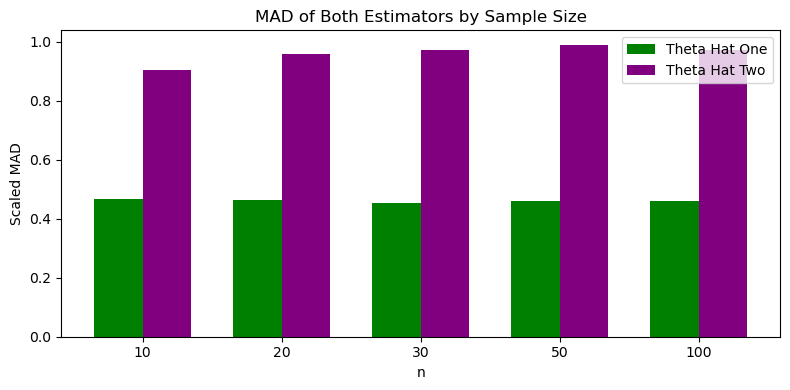

In [268]:
x = np.arange(len(n_samples))
width = 0.35

fig, ax = plt.subplots(figsize=(8, 4))

ax.bar(x - width/2, mad['theta_hat_one'], width, color='green', label='Theta Hat One')
ax.bar(x + width/2, mad['theta_hat_two'], width, color='purple', label='Theta Hat Two')

ax.set_xticks(x)
ax.set_xticklabels(n_samples)
ax.set_xlabel('n')
ax.set_ylabel('Scaled MAD')
ax.set_title('MAD of Both Estimators by Sample Size')
ax.legend()

plt.tight_layout()
plt.show()